https://www.tensorflow.org/tutorials/structured_data/time_series

In [ ]:
import os
import datetime

import IPython
import IPython.display
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

mpl.rcParams['figure.figsize'] = (8, 6)
mpl.rcParams['axes.grid'] = False


I0000 00:00:1794477009.677362 1219256 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794477009.712280 1219256 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794477010.449581 1219256 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [27]:
data_0 = pd.read_csv("processed_data/16Oct_data_corrected.csv", dtype="float32")
data_1 = pd.read_csv("processed_data/27Oct_data.csv", dtype="float32")
data_2 = pd.read_csv("processed_data/28Oct_data.csv", dtype="float32")
data_3 = pd.read_csv("processed_data/29Oct_data.csv", dtype="float32")
data_0 = data_0.dropna()
data_1 = data_1.dropna()
data_2 = data_2.dropna()
data_3 = data_3.dropna()
data_list = [ data_1, data_2, data_3] #data_0, #get better results without data_0

df = pd.concat(data_list, ignore_index=True)
# df.rename( columns={'Unnamed: 0':'order'}, inplace=True )
df = df[["s0", "s1", "s2", "cx_mm", "cy_mm"]]
df.head()

# date_time = df["order"] #to help follow the tutorial code
# date_time = pd.to_datetime(df.pop('Date Time'), format='%d.%m.%Y %H:%M:%S')


,s0,s1,s2,cx_mm,cy_mm
0,0.0,0.0,0.0,0.009091,0.000000
1,0.0,0.0,0.0,-0.009091,0.000000
2,6144.0,-8393.0,2249.0,1.972727,1.745455
3,6144.0,-7949.0,1805.0,1.827273,1.727273
4,6144.0,-7506.0,1362.0,1.681818,1.690909


In [67]:
column_indices = {name: i for i, name in enumerate(df.columns)}

n = len(df)
train_df = df[0:int(n*0.7)]
val_df = df[int(n*0.7):int(n*0.9)]
test_df = df[int(n*0.9):]

num_features = df.shape[1]


Normalize the data

The mean and standard deviation should only be computed using the training data so that the models have no access to the values in the validation and test sets.

In [68]:
train_mean = train_df.mean()
train_std = train_df.std()

train_df = (train_df - train_mean) / train_std
val_df = (val_df - train_mean) / train_std
test_df = (test_df - train_mean) / train_std


<h2> Data Windowing

In [70]:
class WindowGenerator():
  def __init__(self, input_width, label_width, shift,
               train_df=train_df, val_df=val_df, test_df=test_df,
               label_columns=None):
    # Store the raw data.
    self.train_df = train_df
    self.val_df = val_df
    self.test_df = test_df

    # Work out the label column indices.
    self.label_columns = label_columns
    if label_columns is not None:
      self.label_columns_indices = {name: i for i, name in
                                    enumerate(label_columns)}
    self.column_indices = {name: i for i, name in
                           enumerate(train_df.columns)}

    # Work out the window parameters.
    self.input_width = input_width
    self.label_width = label_width
    self.shift = shift

    self.total_window_size = input_width + shift

    self.input_slice = slice(0, input_width)
    self.input_indices = np.arange(self.total_window_size)[self.input_slice]

    self.label_start = self.total_window_size - self.label_width
    self.labels_slice = slice(self.label_start, None)
    self.label_indices = np.arange(self.total_window_size)[self.labels_slice]

  def __repr__(self):
    return '\n'.join([
        f'Total window size: {self.total_window_size}',
        f'Input indices: {self.input_indices}',
        f'Label indices: {self.label_indices}',
        f'Label column name(s): {self.label_columns}'])


In [73]:
w2 = WindowGenerator(input_width=6, label_width=1, shift=1,
                     label_columns=['s0'])
w2



Total window size: 7
Input indices: [0 1 2 3 4 5]
Label indices: [6]
Label column name(s): ['s0']

<h3> Window splitting

In [75]:
# Stack three slices, the length of the total window.
example_window = tf.stack([np.array(train_df[:w2.total_window_size]),
                           np.array(train_df[100:100+w2.total_window_size]),
                           np.array(train_df[200:200+w2.total_window_size])])

example_inputs, example_labels = w2.split_window(example_window)

print('All shapes are: (batch, time, features)')
print(f'Window shape: {example_window.shape}')
print(f'Inputs shape: {example_inputs.shape}')
print(f'Labels shape: {example_labels.shape}')


All shapes are: (batch, time, features)
Window shape: (3, 7, 5)
Inputs shape: (3, 6, 5)
Labels shape: (3, 1, 1)


In [76]:
w2.example = example_inputs, example_labels


In [ ]:
def plot(self, model=None, plot_col='s0', max_subplots=3):
  inputs, labels = self.example
  plt.figure(figsize=(12, 8))
  plot_col_index = self.column_indices[plot_col]
  max_n = min(max_subplots, len(inputs))
  for n in range(max_n):
    plt.subplot(max_n, 1, n+1)
    plt.ylabel(f'{plot_col} [normed]')
    plt.plot(self.input_indices, inputs[n, :, plot_col_index],
             label='Inputs', marker='.', zorder=-10)

    if self.label_columns:
      label_col_index = self.label_columns_indices.get(plot_col, None)
    else:
      label_col_index = plot_col_index

    if label_col_index is None:
      continue

    plt.scatter(self.label_indices, labels[n, :, label_col_index],
                edgecolors='k', label='Labels', c='#2ca02c', s=64)
    if model is not None:
      predictions = model(inputs)
      plt.scatter(self.label_indices, predictions[n, :, label_col_index],
                  marker='X', edgecolors='k', label='Predictions',
                  c='#ff7f0e', s=64)

    if n == 0:
      plt.legend()

  plt.xlabel('Time')

WindowGenerator.plot = plot


<h3> Create tf.data.Datasets</h3>
Finally, this make_dataset method will take a time series DataFrame and convert it to a tf.data.Dataset of (input_window, label_window) pairs using the tf.keras.utils.timeseries_dataset_from_array function:

In [81]:
def make_dataset(self, data):
  data = np.array(data, dtype=np.float32)
  ds = tf.keras.utils.timeseries_dataset_from_array(
      data=data,
      targets=None,
      sequence_length=self.total_window_size,
      sequence_stride=1,
      shuffle=True,
      batch_size=32,)

  ds = ds.map(self.split_window)

  return ds

WindowGenerator.make_dataset = make_dataset


The WindowGenerator object holds training, validation, and test data.

Add properties for accessing them as tf.data.Datasets using the make_dataset method you defined earlier. Also, add a standard example batch for easy access and plotting:

In [82]:
@property
def train(self):
  return self.make_dataset(self.train_df)

@property
def val(self):
  return self.make_dataset(self.val_df)

@property
def test(self):
  return self.make_dataset(self.test_df)

@property
def example(self):
  """Get and cache an example batch of `inputs, labels` for plotting."""
  result = getattr(self, '_example', None)
  if result is None:
    # No example batch was found, so get one from the `.train` dataset
    result = next(iter(self.train))
    # And cache it for next time
    self._example = result
  return result

WindowGenerator.train = train
WindowGenerator.val = val
WindowGenerator.test = test
WindowGenerator.example = example


In [83]:
# Each element is an (inputs, label) pair.
w2.train.element_spec


(TensorSpec(shape=(None, 6, 5), dtype=tf.float32, name=None),
 TensorSpec(shape=(None, 1, 1), dtype=tf.float32, name=None))

In [84]:
for example_inputs, example_labels in w2.train.take(1):
  print(f'Inputs shape (batch, time, features): {example_inputs.shape}')
  print(f'Labels shape (batch, time, features): {example_labels.shape}')


Inputs shape (batch, time, features): (32, 6, 5)
Labels shape (batch, time, features): (32, 1, 1)


<h1>Single step models</h1>
predict single feature's value for the next time step, only based on the current time step

In [85]:
single_step_window = WindowGenerator(
    input_width=1, label_width=1, shift=1,
    label_columns=['s0'])
single_step_window


Total window size: 2
Input indices: [0]
Label indices: [1]
Label column name(s): ['s0']

In [86]:
for example_inputs, example_labels in single_step_window.train.take(1):
  print(f'Inputs shape (batch, time, features): {example_inputs.shape}')
  print(f'Labels shape (batch, time, features): {example_labels.shape}')


Inputs shape (batch, time, features): (32, 1, 5)
Labels shape (batch, time, features): (32, 1, 1)


In [ ]:
wide_window = WindowGenerator(
    input_width=10, label_width=10, shift=1,
    label_columns=['s0'])

wide_window


Total window size: 25
Input indices: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
Label indices: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]
Label column name(s): ['s0']

In [92]:
MAX_EPOCHS = 20

def compile_and_fit(model, window, patience=2):
  early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss',
                                                    patience=patience,
                                                    mode='min')

  model.compile(loss=tf.keras.losses.MeanSquaredError(),
                optimizer=tf.keras.optimizers.Adam(),
                metrics=[tf.keras.metrics.MeanAbsoluteError()])

  history = model.fit(window.train, epochs=MAX_EPOCHS,
                      validation_data=window.val,
                      callbacks=[early_stopping])
  return history


<h2> Multi-step Dense

In [97]:
CONV_WIDTH = 3
conv_window = WindowGenerator(
    input_width=CONV_WIDTH,
    label_width=1,
    shift=1,
    label_columns=['s0'])

conv_window


Total window size: 4
Input indices: [0 1 2]
Label indices: [3]
Label column name(s): ['s0']

Text(0.5, 0.98, 'Given 3 seconds of inputs, predict 1 second into the future.')

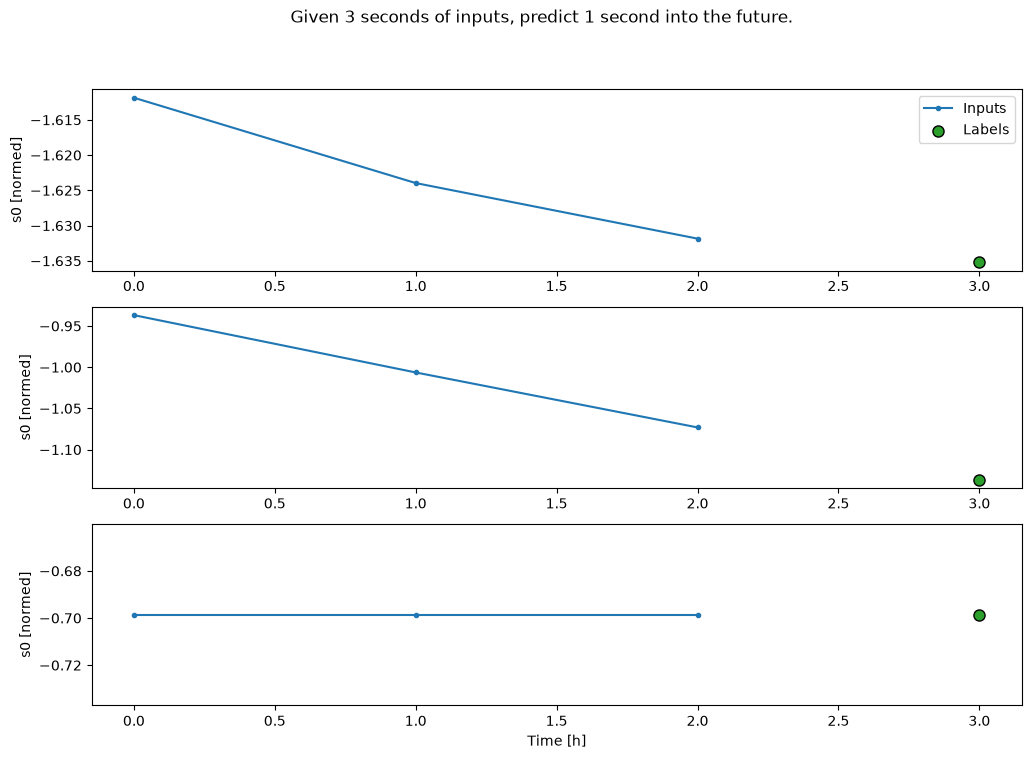

In [98]:
conv_window.plot()
plt.suptitle("Given 3 seconds of inputs, predict 1 second into the future.")


You could train a dense model on a multiple-input-step window by adding a tf.keras.layers.Flatten as the first layer of the model:

In [99]:
multi_step_dense = tf.keras.Sequential([
    # Shape: (time, features) => (time*features)
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=32, activation='relu'),
    tf.keras.layers.Dense(units=32, activation='relu'),
    tf.keras.layers.Dense(units=1),
    # Add back the time dimension.
    # Shape: (outputs) => (1, outputs)
    tf.keras.layers.Reshape([1, -1]),
])
print('Input shape:', conv_window.example[0].shape)
print('Output shape:', multi_step_dense(conv_window.example[0]).shape)


Input shape: (32, 3, 5)
Output shape: (32, 1, 1)


In [100]:
history = compile_and_fit(multi_step_dense, conv_window)

IPython.display.clear_output()
val_performance['Multi step dense'] = multi_step_dense.evaluate(conv_window.val, return_dict=True)
performance['Multi step dense'] = multi_step_dense.evaluate(conv_window.test, verbose=0, return_dict=True)


57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 725us/step - loss: 0.0024 - mean_absolute_error: 0.0253   


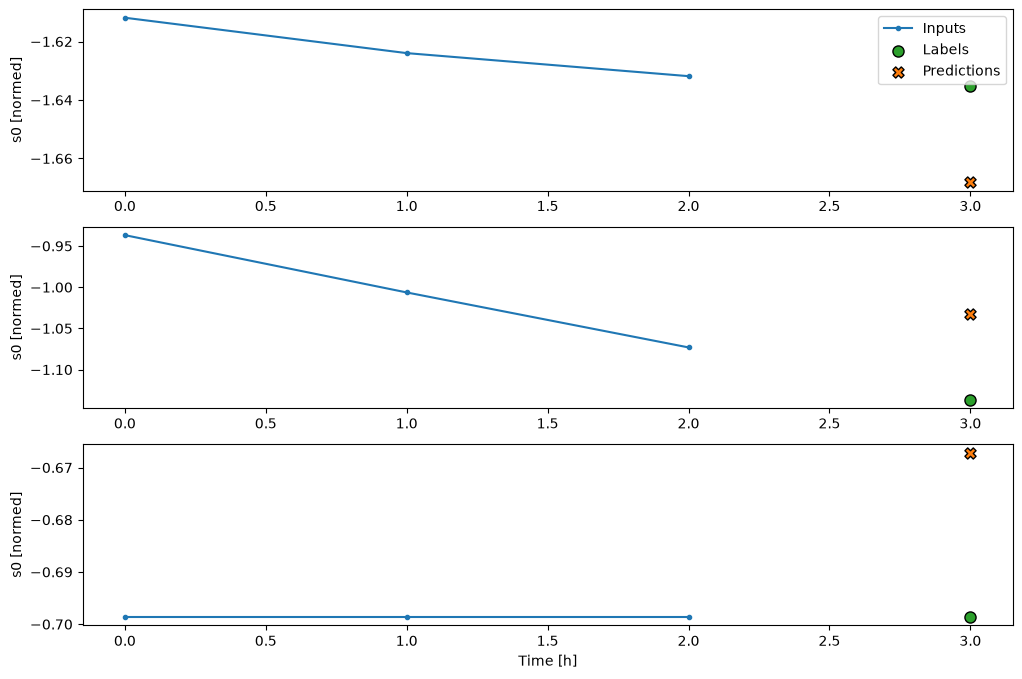

In [101]:
conv_window.plot(multi_step_dense)


Can only use this model on input windows of the exact same shape

In [103]:
print('Input shape:', wide_window.example[0].shape)
try:
  print('Output shape:', multi_step_dense(wide_window.example[0]).shape)
except Exception as e:
  print(f'\n{type(e).__name__}:{e}')


Input shape: (32, 24, 5)

ValueError:Exception encountered when calling Sequential.call().

Input 0 with name 'None' of layer 'dense_4' is incompatible with the layer: expected axis -1 of input shape to have value 15, but received input with shape (32, 120)

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(32, 24, 5), dtype=float32)
  • training=None
  • mask=None
  • kwargs=<class 'inspect._empty'>


<h1> Recurrent Neural Network - LSTM</h1>
An important constructor argument for all Keras RNN layers, such as tf.keras.layers.LSTM, is the return_sequences argument. This setting can configure the layer in one of two ways:

    If False, the default, the layer only returns the output of the final time step, giving the model time to warm up its internal state before making a single prediction:

An LSTM warming up and making a single prediction

    If True, the layer returns an output for each input. This is useful for:
        Stacking RNN layers.
        Training a model on multiple time steps simultaneously.


In [ ]:
lstm_model = tf.keras.models.Sequential([
    # Shape [batch, time, features] => [batch, time, lstm_units]
    tf.keras.layers.LSTM(32, return_sequences=True),
    # Shape => [batch, time, features]
    tf.keras.layers.Dense(units=1)
])
print('Input shape:', wide_window.example[0].shape)
print('Output shape:', lstm_model(wide_window.example[0]).shape)

Input shape: (32, 24, 5)
Output shape: (32, 24, 1)


Note: This will give a pessimistic view of the model's performance. On the first time step, the model has no access to previous steps and, therefore, can't do any better than the simple linear and dense models shown earlier.

57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0031 - mean_absolute_error: 0.0258


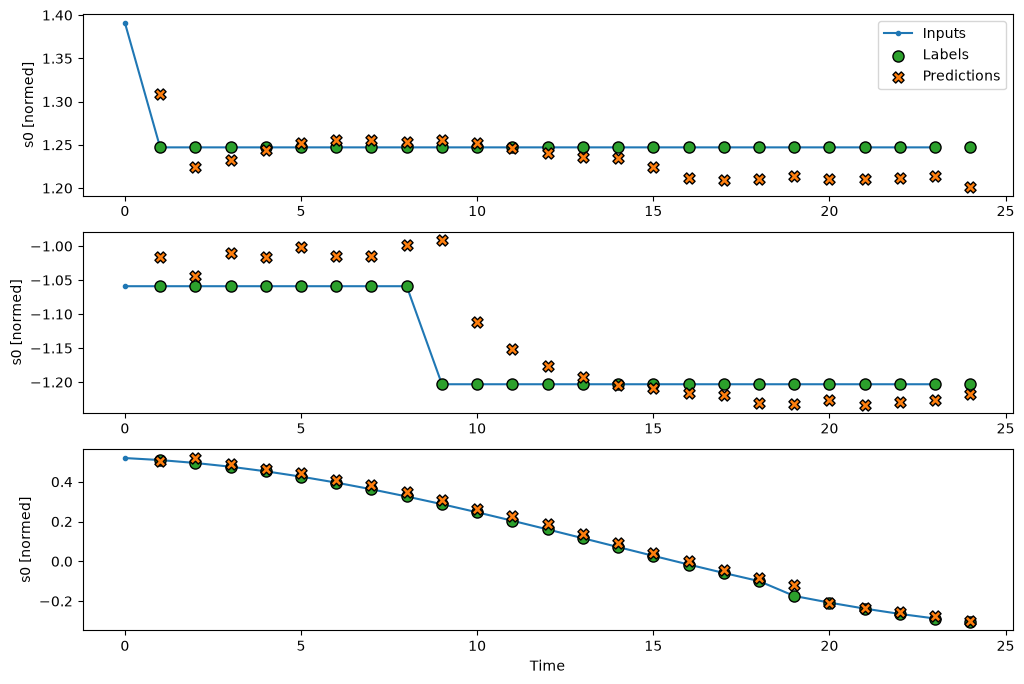

In [ ]:
history = compile_and_fit(lstm_model, wide_window)
val_performance = {}
performance = {}
IPython.display.clear_output()
val_performance['LSTM'] = lstm_model.evaluate(wide_window.val, return_dict=True)
performance['LSTM'] = lstm_model.evaluate(wide_window.test, verbose=0, return_dict=True)
wide_window.plot(lstm_model)


In [115]:
cm = lstm_model.metrics[1]
cm.metrics


[<MeanAbsoluteError name=mean_absolute_error>]

In [116]:
val_performance


{'Baseline': {'loss': 0.0025009980890899897,
  'mean_absolute_error': 0.008081991225481033},
 'Linear': {'loss': 0.004838951397687197,
  'mean_absolute_error': 0.04639911279082298},
 'Dense': {'loss': 0.0027150975074619055,
  'mean_absolute_error': 0.020444033667445183},
 'Multi step dense': {'loss': 0.0023756236769258976,
  'mean_absolute_error': 0.02527019940316677},
 'Conv': {'loss': 0.0029838557820767164,
  'mean_absolute_error': 0.028803078457713127},
 'LSTM': {'loss': 0.0031118423212319613,
  'mean_absolute_error': 0.025755733251571655}}

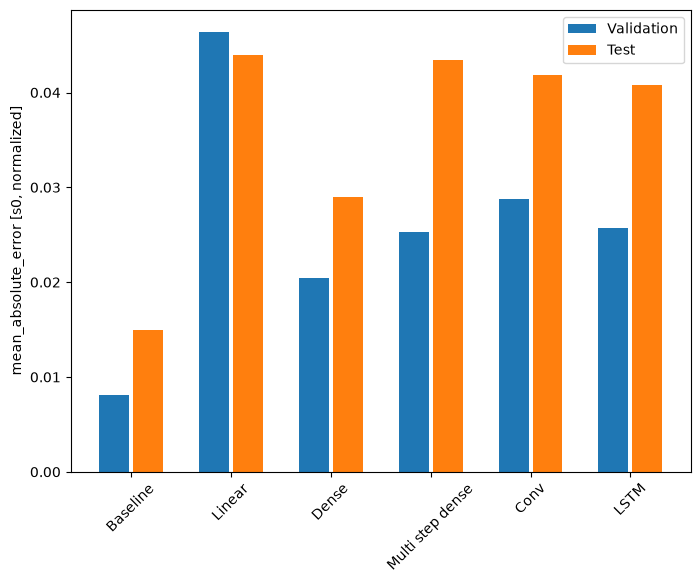

In [118]:
x = np.arange(len(performance))
width = 0.3
metric_name = 'mean_absolute_error'
val_mae = [v[metric_name] for v in val_performance.values()]
test_mae = [v[metric_name] for v in performance.values()]

plt.ylabel('mean_absolute_error [s0, normalized]')
plt.bar(x - 0.17, val_mae, width, label='Validation')
plt.bar(x + 0.17, test_mae, width, label='Test')
plt.xticks(ticks=x, labels=performance.keys(),
           rotation=45)
_ = plt.legend()


In [119]:
for name, value in performance.items():
  print(f'{name:12s}: {value[metric_name]:0.4f}')


Baseline    : 0.0149
Linear      : 0.0439
Dense       : 0.0290
Multi step dense: 0.0434
Conv        : 0.0419
LSTM        : 0.0408


The baseline model actually performed best for s0 - this is probably due to the snake scans - s0 stays constant for each row. It would work less well for s1 or s2